In [2]:
import os
import random
import json

random.seed(42)

data_dir = '/kaggle/input/noisy-audio-mnist/'
output_dir = '/kaggle/working/'

noisy_files = []
clean_files = []

for folder in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, folder)
    if os.path.isdir(folder_path):
        for file in os.listdir(folder_path):
            if file.endswith('_noisy.wav'):
                noisy_files.append(os.path.join(folder_path, file))
                clean_filename = file.replace('_noisy.wav', '.wav')
                clean_files.append(os.path.join(folder_path, clean_filename))

paired_files = list(zip(noisy_files, clean_files))
random.shuffle(paired_files)

train_size = int(0.8 * len(paired_files))
val_size = int(0.1 * len(paired_files))

train_data = paired_files[:train_size]
val_data = paired_files[train_size:train_size + val_size]
test_data = paired_files[train_size + val_size:]

print(f"Training set size: {len(train_data)}")
print(f"Validation set size: {len(val_data)}")
print(f"Test set size: {len(test_data)}")

split_data = {
    'train': train_data,
    'val': val_data,
    'test': test_data
}

with open(os.path.join(output_dir, 'dataset_splits.json'), 'w') as f:
    json.dump(split_data, f)

print("Dataset splits saved to 'dataset_splits.json'")


Training set size: 24000
Validation set size: 3000
Test set size: 3000
Dataset splits saved to 'dataset_splits.json'


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super(UNet, self).__init__()
        
        self.enc1 = self.conv_block(in_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)

        self.bottleneck = self.conv_block(512, 1024)

        self.dec4 = self.upconv_block(1024, 512)
        self.dec3 = self.upconv_block(1024, 256)
        self.dec2 = self.upconv_block(512, 128)
        self.dec1 = self.upconv_block(256, 64)

        self.reduce_channels = nn.Conv2d(128, 64, kernel_size=3, padding=1)

        self.final = nn.Conv2d(64, out_channels, kernel_size=1)
    
    def conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    
    def upconv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    
    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(nn.MaxPool2d(2)(enc1))
        enc3 = self.enc3(nn.MaxPool2d(2)(enc2))
        enc4 = self.enc4(nn.MaxPool2d(2)(enc3))
    
        bottleneck = self.bottleneck(nn.MaxPool2d(2)(enc4))
    
        dec4 = self.dec4(bottleneck)
        dec4 = torch.cat((dec4, crop_tensor(enc4, dec4)), dim=1)
    
        dec3 = self.dec3(dec4)
        dec3 = torch.cat((dec3, crop_tensor(enc3, dec3)), dim=1)
    
        dec2 = self.dec2(dec3)
        dec2 = torch.cat((dec2, crop_tensor(enc2, dec2)), dim=1)
    
        dec1 = self.dec1(dec2)
        dec1 = torch.cat((dec1, crop_tensor(enc1, dec1)), dim=1)
    
        dec1 = self.reduce_channels(dec1)
    
        out = self.final(dec1)
    
        out = F.interpolate(out, size=(x.size(2), x.size(3)), mode='bilinear', align_corners=False)
    
        return out


In [4]:
def crop_tensor(tensor, target_tensor):
    _, _, h, w = tensor.size()
    _, _, target_h, target_w = target_tensor.size()

    crop_h = (h - target_h) // 2
    crop_w = (w - target_w) // 2

    return tensor[:, :, crop_h:crop_h + target_h, crop_w:crop_w + target_w]

In [12]:
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

class AudioDenoisingDataset(Dataset):
    def __init__(self, data, sr=48000, n_mels=128, hop_length=512, n_fft=2048, target_shape=(128, 100)):
        self.data = data
        self.sr = sr
        self.n_mels = n_mels
        self.hop_length = hop_length
        self.n_fft = n_fft
        self.target_shape = target_shape

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        noisy_path, clean_path = self.data[idx]

        noisy_spectrogram = self.generate_mel_spectrogram(noisy_path)
        clean_spectrogram = self.generate_mel_spectrogram(clean_path)

        noisy_tensor = torch.tensor(noisy_spectrogram).float().unsqueeze(0)
        clean_tensor = torch.tensor(clean_spectrogram).float().unsqueeze(0)

        return noisy_tensor, clean_tensor, {"noisy_path": noisy_path, "clean_path": clean_path}

    def generate_mel_spectrogram(self, audio_path):
        y, _ = librosa.load(audio_path, sr=self.sr)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=self.sr, n_mels=self.n_mels, hop_length=self.hop_length, n_fft=self.n_fft)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        mel_spec_norm = (mel_spec_db - mel_spec_db.min()) / (mel_spec_db.max() - mel_spec_db.min())
        return zoom(mel_spec_norm, (self.target_shape[0] / mel_spec_norm.shape[0], self.target_shape[1] / mel_spec_norm.shape[1]))

In [13]:
model = UNet(in_channels=1, out_channels=1) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.load_state_dict(torch.load("/kaggle/input/audiov2/pytorch/default/1/unet_audio_denoising_reconstructable.pth"))
model = model.to(device)

/tmp/ipykernel_30/4264729410.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("/kaggle/input/audiov2/pytorch/default/1/unet_audio_denoisi

Evaluating origin: Europe, Germany, Freiburg: 100%|██████████| 3/3 [00:01<00:00,  1.83it/s]
Evaluating origin: South-America, Brazil, Porto Alegre: 100%|██████████| 4/4 [00:01<00:00,  2.12it/s]
Evaluating origin: Europe, Spain, Toledo: 100%|██████████| 4/4 [00:01<00:00,  2.17it/s]
Evaluating origin: Europe, Germany, Alsbach-Haehnlein: 100%|██████████| 4/4 [00:01<00:00,  2.30it/s]
Evaluating recordingroom: VR-Room: 100%|██████████| 14/14 [00:07<00:00,  1.93it/s]



Group: accent
  Chinese: SNR Improvement Mean: 7.12 dB, Std: 1.38 dB, Samples: 165
  German: SNR Improvement Mean: 7.04 dB, Std: 1.60 dB, Samples: 1998
  French: SNR Improvement Mean: 6.41 dB, Std: 1.31 dB, Samples: 49
  Madras: SNR Improvement Mean: 6.47 dB, Std: 1.53 dB, Samples: 48
  Egyptian_American?: SNR Improvement Mean: 6.82 dB, Std: 1.41 dB, Samples: 49
  South Korean: SNR Improvement Mean: 5.91 dB, Std: 1.57 dB, Samples: 50
  Brasilian: SNR Improvement Mean: 7.11 dB, Std: 1.46 dB, Samples: 54
  Arabic: SNR Improvement Mean: 7.55 dB, Std: 1.23 dB, Samples: 50
  Levant: SNR Improvement Mean: 6.32 dB, Std: 1.49 dB, Samples: 42
  Italian: SNR Improvement Mean: 7.79 dB, Std: 1.29 dB, Samples: 103
  English: SNR Improvement Mean: 6.71 dB, Std: 1.25 dB, Samples: 53
  Spanish: SNR Improvement Mean: 7.36 dB, Std: 1.30 dB, Samples: 106
  German/Spanish: SNR Improvement Mean: 7.50 dB, Std: 0.97 dB, Samples: 48
  german: SNR Improvement Mean: 6.78 dB, Std: 1.36 dB, Samples: 56
  Danish:

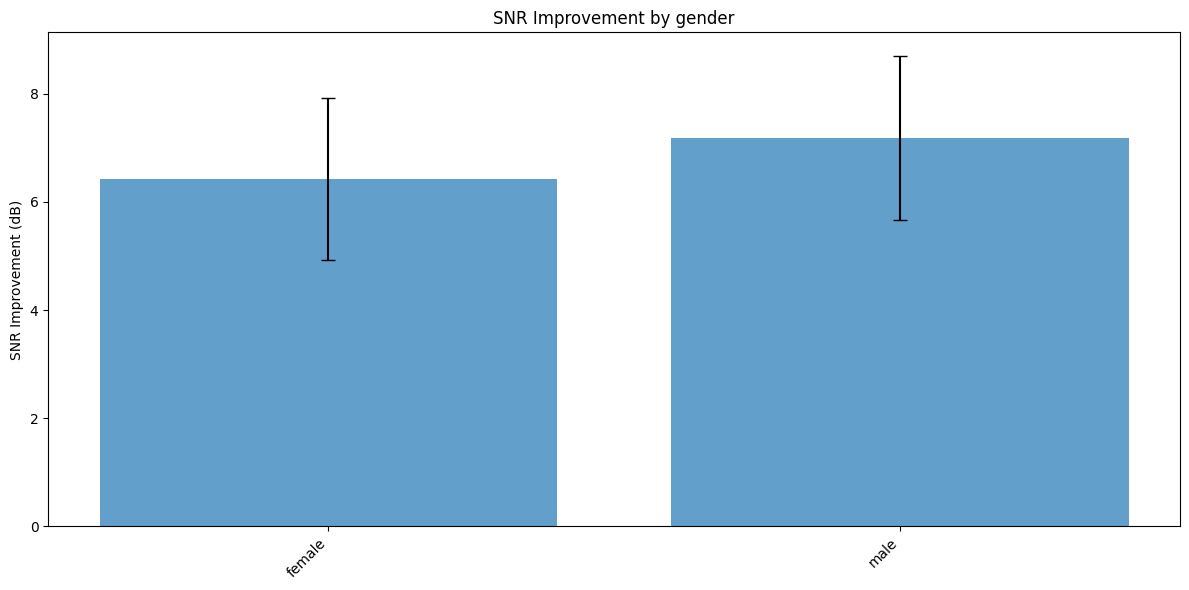

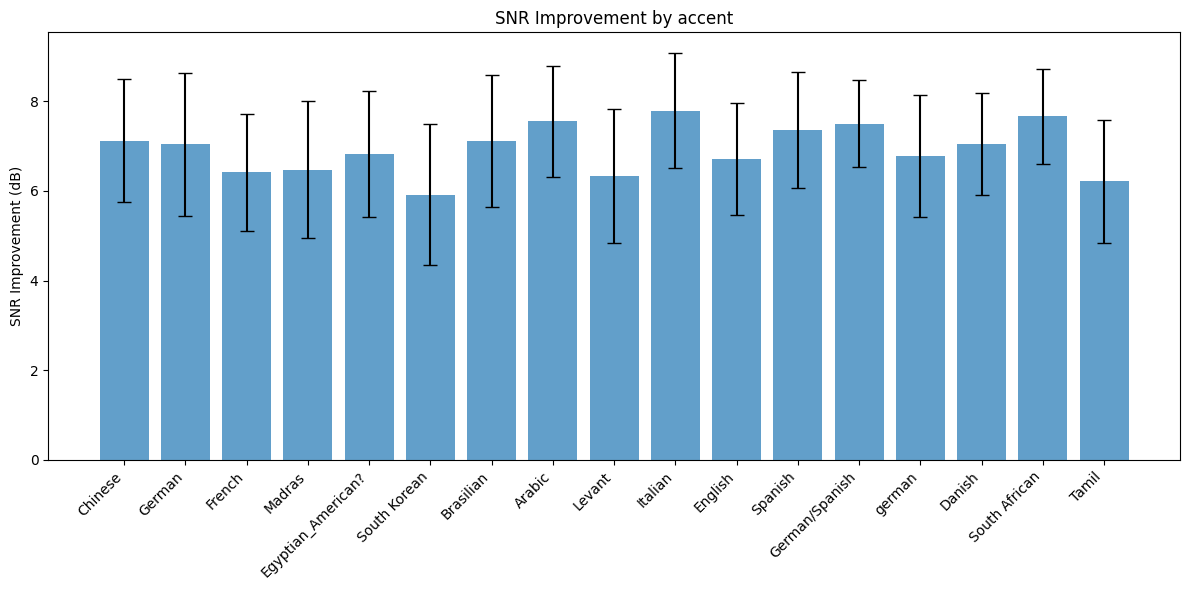

In [19]:
import json
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from tqdm import tqdm
import numpy as np
import librosa
from scipy.ndimage import zoom

metadata_path = "/kaggle/input/noisy-audio-mnist/audioMNIST_meta.txt"
with open(metadata_path, "r") as f:
    metadata = json.load(f)

def group_test_data_by_metadata(test_data, metadata):
    grouped_data = {}
    
    for noisy_path, clean_path in test_data:
        speaker_id = noisy_path.split("/")[-2] 
        speaker_metadata = metadata.get(speaker_id, {})
        
        for key, value in speaker_metadata.items():
            if key not in grouped_data:
                grouped_data[key] = {}
            if value not in grouped_data[key]:
                grouped_data[key][value] = []
            grouped_data[key][value].append((noisy_path, clean_path))
    
    return grouped_data

grouped_test_data = group_test_data_by_metadata(test_data, metadata)

def evaluate_grouped_data(model, grouped_data, device, batch_size=16):
    model.eval()
    results = {}
    
    with torch.no_grad():
        for group, categories in grouped_data.items():
            results[group] = {}
            for category, files in categories.items():
                dataset = AudioDenoisingDataset(files)
                dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
                
                snr_improvements = []
                for noisy, clean, _ in tqdm(dataloader, desc=f"Evaluating {group}: {category}"):
                    noisy, clean = noisy.to(device), clean.to(device)
                    output = model(noisy)
                    
                    # Calculate SNR improvement
                    noisy_power = torch.mean(noisy ** 2, dim=(1, 2, 3))
                    clean_power = torch.mean(clean ** 2, dim=(1, 2, 3))
                    noise_power_before = torch.mean((noisy - clean) ** 2, dim=(1, 2, 3))
                    noise_power_after = torch.mean((output - clean) ** 2, dim=(1, 2, 3))
                    
                    snr_before = 10 * torch.log10(clean_power / noise_power_before)
                    snr_after = 10 * torch.log10(clean_power / noise_power_after)
                    
                    snr_improvement = (snr_after - snr_before).cpu().numpy()
                    snr_improvements.extend(snr_improvement)
                
                results[group][category] = {
                    "snr_improvement_mean": np.mean(snr_improvements),
                    "snr_improvement_std": np.std(snr_improvements),
                    "num_samples": len(files)
                }
    
    return results

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results = evaluate_grouped_data(model, grouped_test_data, device)

for group, categories in results.items():
    print(f"\nGroup: {group}")
    for category, metrics in categories.items():
        print(f"  {category}: SNR Improvement Mean: {metrics['snr_improvement_mean']:.2f} dB, Std: {metrics['snr_improvement_std']:.2f} dB, Samples: {metrics['num_samples']}")

def plot_results(results, group_name):
    categories = list(results[group_name].keys())
    means = [results[group_name][category]["snr_improvement_mean"] for category in categories]
    stds = [results[group_name][category]["snr_improvement_std"] for category in categories]

    x = np.arange(len(categories))
    
    plt.figure(figsize=(12, 6))
    plt.bar(x, means, yerr=stds, capsize=5, alpha=0.7, ecolor='black', label='SNR Improvement')
    plt.xticks(x, categories, rotation=45, ha='right')
    plt.ylabel("SNR Improvement (dB)")
    plt.title(f"SNR Improvement by {group_name}")
    plt.tight_layout()
    plt.show()

plot_results(results, "gender")
plot_results(results, "accent")


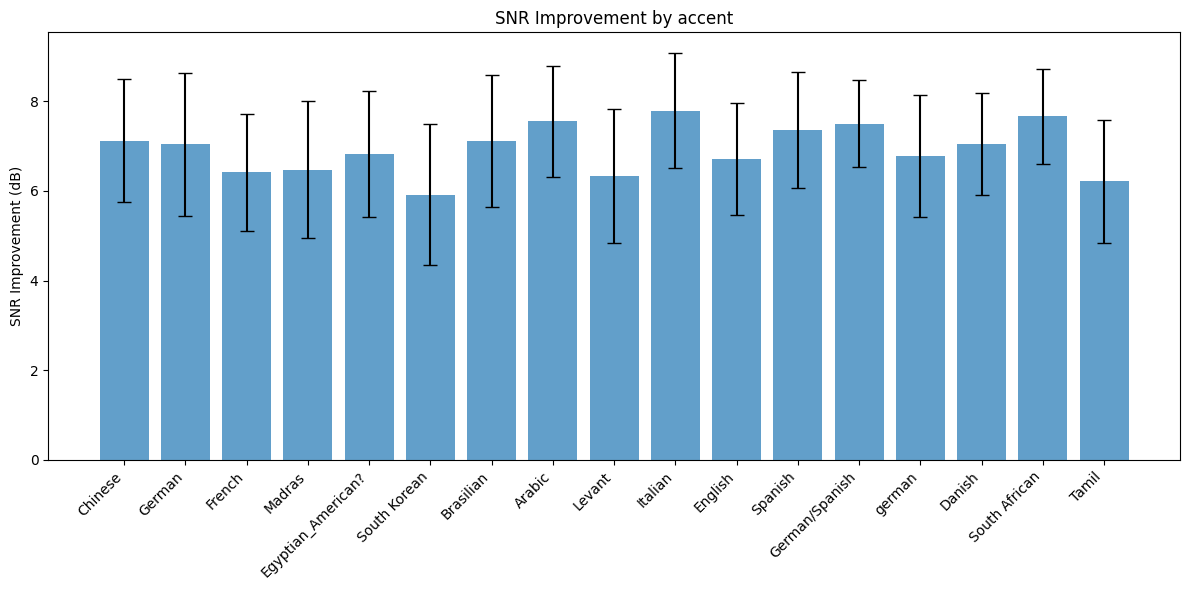

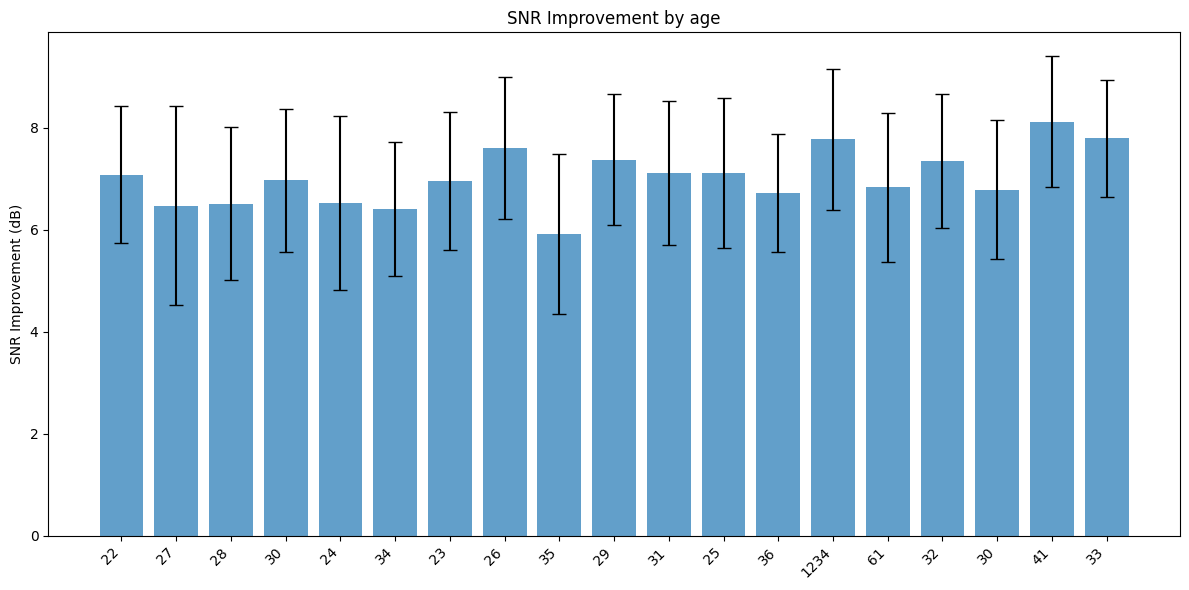

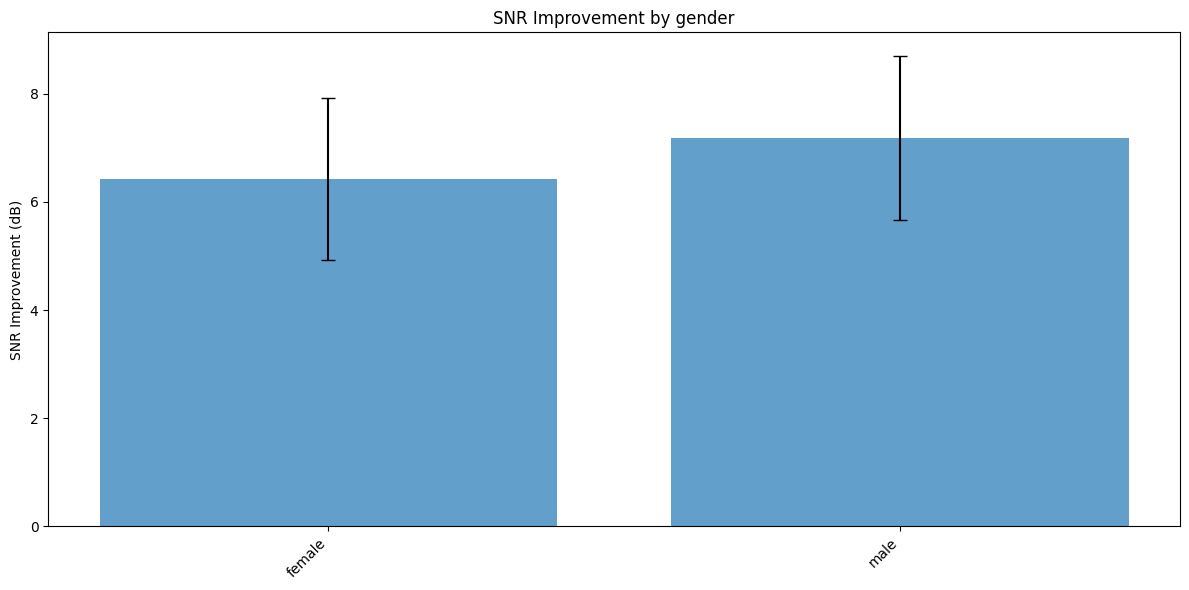

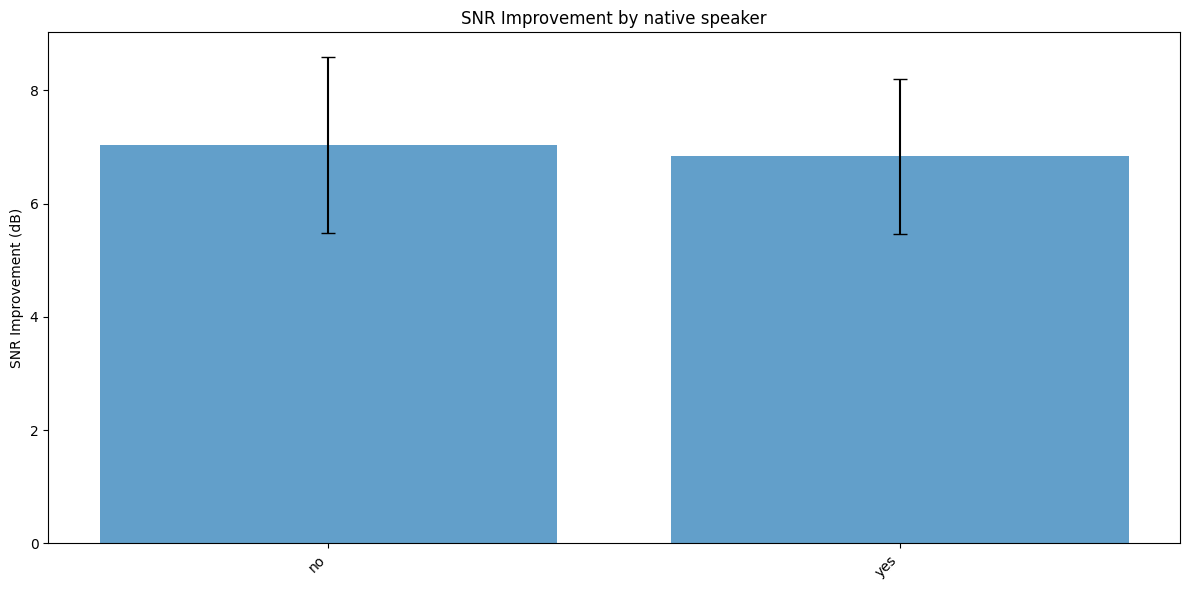

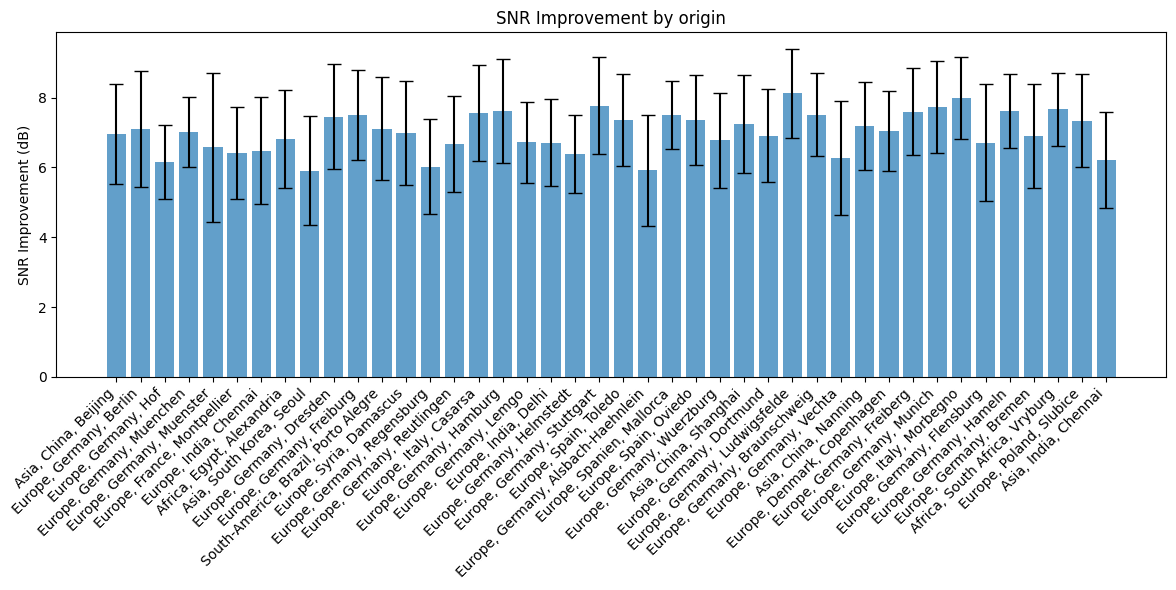

In [21]:
plot_results(results, "accent")
plot_results(results, "age")
plot_results(results, "gender")
plot_results(results, "native speaker")
plot_results(results, "origin")